# Stock risk report (HW2 part 2)

Parameterized template. Papermill swaps in `ticker`, `start_date`, `end_date` and `db_path` from the tagged cell below. It reads `ohlc_hw_cleaned`, which `01_data_cleaning.ipynb` makes.

Conventions I follow (from the hw):
- returns, volatility, Sharpe, drawdown all use **adjusted close**
- daily returns are **log** returns, `log(p_t / p_{t-1})`
- std is the sample std (`ddof=1`), annualized with 252 trading days
- rolling warm-up gaps stay NaN (never filled with 0), and undefined metrics show N/A
- values stay as fractions, I only turn them into % for display

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import display
import scrapbook as sb

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # local working copy made by 01_data_cleaning.ipynb

In [3]:
# Parameters
ticker = "MRK"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "D:\\Berkeley\\Pre-Program Courses\\Python\\UCB-MFE-python-preprogram-2026-winter\\Homeworks\\HW2\\dev_rao\\data\\data.db"


In [4]:
VOL_WINDOW = 20        # returns in the rolling volatility window
MA_WINDOW = 50         # prices in the moving average
RISK_FREE_RATE = 0.02  # annual, course convention
TRADING_DAYS = 252

# shared colours so all four panels match
GREEN, RED, GRAY = '#2e7d32', '#c62828', '#9e9e9e'
NAVY, PURPLE = '#1a237e', '#6a1b9a'

## loading the data

Input checks first: the db has to exist, the dates have to parse and be in order, and there have to be enough rows. 20 returns need at least 21 prices, otherwise the 20-day volatility never gets a full window and I'd rather fail loudly than show an empty chart.

In [5]:
ticker = str(ticker).strip().upper()
if not ticker:
    raise ValueError('ticker is empty')
start_ts, end_ts = pd.Timestamp(start_date), pd.Timestamp(end_date)
if start_ts > end_ts:
    raise ValueError(f'start_date {start_date} is after end_date {end_date}')

database = Path(db_path).expanduser()
if not database.is_absolute():
    database = Path.cwd() / database
database = database.resolve()
if not database.is_file():
    raise FileNotFoundError(f'no database at {database}, run 01_data_cleaning.ipynb first')

query = '''
SELECT ts, open, high, low, close, adj_close, volume, adj_close_source, extreme_return_flag
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
'''
with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", conn)['name'].tolist()
    if 'ohlc_hw_cleaned' not in tables:
        raise ValueError('ohlc_hw_cleaned not found, run 01_data_cleaning.ipynb first')
    df = pd.read_sql_query(query, conn, params=(ticker, start_ts.strftime('%Y-%m-%d'), end_ts.strftime('%Y-%m-%d')),
                           parse_dates=['ts'], index_col='ts')
    ticker_history = pd.read_sql_query('SELECT MIN(ts) AS first, MAX(ts) AS last FROM ohlc_hw_cleaned WHERE ticker = ?',
                                       conn, params=(ticker,)).iloc[0]

if df.empty:
    raise ValueError(f'{ticker}: no rows in ohlc_hw_cleaned between {start_date} and {end_date}')

first_obs, last_obs = df.index.min(), df.index.max()
n_days = len(df)
print(f'{ticker} from {start_date} to {end_date}: {n_days} trading days')
print(f'actual first / last observation: {first_obs.date()} / {last_obs.date()}')
if n_days < VOL_WINDOW + 1:
    raise ValueError(f'{ticker}: insufficient history, {n_days} prices in the window but need at least {VOL_WINDOW + 1} '
                     f'for {VOL_WINDOW} returns')
display(df.head())
display(df.tail())

MRK from 2024-06-01 to 2024-11-30: 126 trading days
actual first / last observation: 2024-06-03 / 2024-11-29


,open,high,low,close,adj_close,volume,adj_close_source,extreme_return_flag
ts,,,,,,,,
2024-06-03,125.77,128.95,125.77,128.42,126.81,7702676,vendor,0
2024-06-04,127.15,129.36,126.88,128.71,127.09,6440167,vendor,0
2024-06-05,128.48,129.94,128.07,129.45,127.82,5009502,vendor,0
2024-06-06,129.16,130.93,128.90,130.52,128.88,8088641,vendor,0
2024-06-07,130.35,131.37,130.21,130.67,129.03,4945600,vendor,0


,open,high,low,close,adj_close,volume,adj_close_source,extreme_return_flag
ts,,,,,,,,
2024-11-22,100.33,101.79,98.93,99.18,99.18,14031200,vendor,0
2024-11-25,100.09,101.74,99.51,101.16,101.16,34659100,ohlc_factor_x_close,0
2024-11-26,101.48,101.80,99.70,101.62,101.62,9324100,vendor,0
2024-11-27,101.65,103.45,101.64,103.12,103.12,9802200,vendor,0
2024-11-29,102.88,103.04,101.53,101.64,101.64,6081200,vendor,0


### coverage

The requested window isn't always what we actually have. Some tickers' histories stop before the window ends (a lot of them end on 2024-10-18), so I spell it out instead of letting the title suggest the full period.

In [6]:
coverage_notes = []
if (last_obs - end_ts).days < -7:
    coverage_notes.append(f"data ends {last_obs.date()} ({(end_ts - last_obs).days} calendar days before the requested end "
                          f"{end_ts.date()}; {ticker}'s history in the db ends {ticker_history['last']})")
if (first_obs - start_ts).days > 7:
    coverage_notes.append(f'data starts {first_obs.date()}, after the requested start {start_ts.date()} '
                          f"({ticker}'s history starts {ticker_history['first']})")
coverage_note = '; '.join(coverage_notes) if coverage_notes else 'full coverage of the requested window'
short_coverage = bool(coverage_notes)
print('coverage:', coverage_note)
if short_coverage:
    print('-> metrics below only cover the observed dates, so compare with other stocks carefully')

coverage: full coverage of the requested window


### input checks

Same checks as lecture: missing/non-finite values, nonpositive prices, OHLC bounds, negative volume, duplicate dates. Part 1 should already guarantee all of this, but the report shouldn't just trust its input. I also count how many adj_close values in this window were rebuilt in part 1, so it's visible.

In [7]:
def quality_flags(frame: pd.DataFrame) -> pd.DataFrame:
    # True where a row has a problem; raw OHLC bounds don't apply to adj_close
    price_cols = ['open', 'high', 'low', 'close', 'adj_close']
    flags = pd.DataFrame(index=frame.index)
    flags['missing_or_nonfinite'] = ~np.isfinite(frame[price_cols + ['volume']]).all(axis=1)
    flags['nonpositive_price'] = frame[price_cols].le(0).any(axis=1)
    flags['ohlc_bounds'] = (frame['high'].lt(frame[['open', 'close']].max(axis=1))
                            | frame['low'].gt(frame[['open', 'close']].min(axis=1))
                            | frame['high'].lt(frame['low']))
    flags['negative_volume'] = frame['volume'].lt(0)
    flags['duplicate_date'] = frame.index.duplicated(keep=False)
    return flags


quality = quality_flags(df)
display(quality.sum().to_frame('rows flagged'))
data_quality_ok = bool(not quality.any().any())
if not data_quality_ok:
    raise ValueError('data quality checks failed: ' + str(quality.sum().to_dict()))
assert df.index.is_monotonic_increasing
print('adj_close source in this window:', df['adj_close_source'].value_counts().to_dict())
print('3 sigma review flags in this window (from part 1, kept as is):', int(df['extreme_return_flag'].sum()))

,rows flagged
missing_or_nonfinite,0
nonpositive_price,0
ohlc_bounds,0
negative_volume,0
duplicate_date,0


adj_close source in this window: {'vendor': 117, 'ohlc_factor_x_close': 9}
3 sigma review flags in this window (from part 1, kept as is): 1


## risk metrics

In [8]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    '''Daily log returns: log(p_t / p_{t-1}).

    prices: adjusted close, sorted by date, all > 0.
    The first value is NaN since there's no previous price. It's left as NaN, not 0.
    '''
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    '''Annualized rolling volatility.

    Sample std (ddof=1) of the last `window` daily log returns times sqrt(252).
    NaN until a full window of returns exists (warm-up isn't filled).
    '''
    return returns.rolling(window).std(ddof=1) * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    '''Per-date drawdown from the running peak: (price - cummax) / cummax.

    Name is from the hw but the output is the drawdown series (it can recover).
    The maximum drawdown is drawdown.min().
    '''
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    '''Annualized Sharpe ratio, course version: (mean * 252 - rf) / (std * sqrt(252)).

    returns: daily log returns (NaNs get dropped). Returns NaN if there are fewer than
    2 returns or the volatility is zero / undefined.
    '''
    observed = returns.dropna()
    if len(observed) < 2:
        return np.nan
    sigma = observed.std(ddof=1)
    if not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS))


def annualized_return(returns: pd.Series) -> float:
    '''Compounded annualized return from n daily log returns: exp(sum * 252 / n) - 1.'''
    observed = returns.dropna()
    if observed.empty:
        return np.nan
    return float(np.expm1(observed.sum() * TRADING_DAYS / len(observed)))

quick sanity checks on numbers I can do by hand:
- 100 -> 110 -> 99: log returns are log(1.1) and log(0.9), and they add up to log(0.99), i.e. total -1%
- 80 -> 100 -> 70 -> 85: the worst drawdown is -30% (70 vs the 100 peak) but the final one is only -15%
- a constant return has zero volatility, so the Sharpe should be NaN
- the 20-day vol needs 21 prices, so the first 20 values are NaN

In [9]:
toy = calculate_returns(pd.Series([100.0, 110.0, 99.0]))
assert pd.isna(toy.iloc[0]) and np.isclose(toy.iloc[1], np.log(1.1)) and np.isclose(np.expm1(toy.sum()), -0.01)
dd_toy = calculate_max_drawdown(pd.Series([80.0, 100.0, 70.0, 85.0]))
assert np.isclose(dd_toy.min(), -0.30) and np.isclose(dd_toy.iloc[-1], -0.15)
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))
vol_toy = calculate_volatility(calculate_returns(pd.Series(np.linspace(100, 130, 25))), 20)
assert vol_toy.iloc[:20].isna().all() and vol_toy.iloc[20:].notna().all()
print('hand checks pass')

hand checks pass


In [10]:
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'], VOL_WINDOW)
df['drawdown'] = calculate_max_drawdown(df['adj_close'])
df['ma_50'] = df['adj_close'].rolling(MA_WINDOW).mean()   # NaN until 50 prices exist

returns = df['log_return'].dropna()
n_returns = len(returns)
mean_rolling_vol = df['volatility'].mean()   # only over dates that have an estimate

total_return = df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1
ann_return = annualized_return(returns)
ann_vol = returns.std(ddof=1) * np.sqrt(TRADING_DAYS) if n_returns >= 2 else np.nan
sharpe = calculate_sharpe_ratio(returns, RISK_FREE_RATE)
max_dd = df['drawdown'].min()
max_dd_date = df['drawdown'].idxmin()
up, down = returns[returns > 0], returns[returns < 0]

print(f'returns used: {n_returns} (first price has no return)')
print(f'rolling vol estimates: {df["volatility"].notna().sum()} of {n_days} dates (first {VOL_WINDOW} are warm-up)')
print(f'50-day MA available on {df["ma_50"].notna().sum()} of {n_days} dates')
print(f'Sharpe ratio: {sharpe:.3f}' if pd.notna(sharpe) else 'Sharpe ratio: N/A')
print(f'max drawdown: {max_dd:.2%} on {max_dd_date.date()}')
display(df[['adj_close', 'log_return', 'volatility', 'drawdown', 'ma_50']].iloc[[0, 1, VOL_WINDOW - 1, VOL_WINDOW, -1]])

returns used: 125 (first price has no return)
rolling vol estimates: 106 of 126 dates (first 20 are warm-up)
50-day MA available on 77 of 126 dates
Sharpe ratio: -1.934
max drawdown: -27.08% on 2024-11-15


,adj_close,log_return,volatility,drawdown,ma_50
ts,,,,,
2024-06-03,126.81,NaN,NaN,0.000000,NaN
2024-06-04,127.09,0.002206,NaN,0.000000,NaN
2024-07-01,127.05,0.032559,NaN,-0.038083,NaN
2024-07-02,126.87,-0.001418,0.246352,-0.039446,NaN
2024-11-29,101.64,-0.014456,0.211341,-0.230466,105.807


## charts

- **price**: each segment is coloured by that day's rolling vol vs the mean rolling vol over the report (red = above the mean, green = at/below it, gray = warm-up with no estimate yet). The threshold uses the whole report period, so the colouring is in hindsight
- **returns**: daily log returns, green up and red down
- **volatility**: 20-day rolling vol, dashed line at its mean, shaded red above / green below
- **drawdown**: layered transparent red fills for the gradient, worst point marked

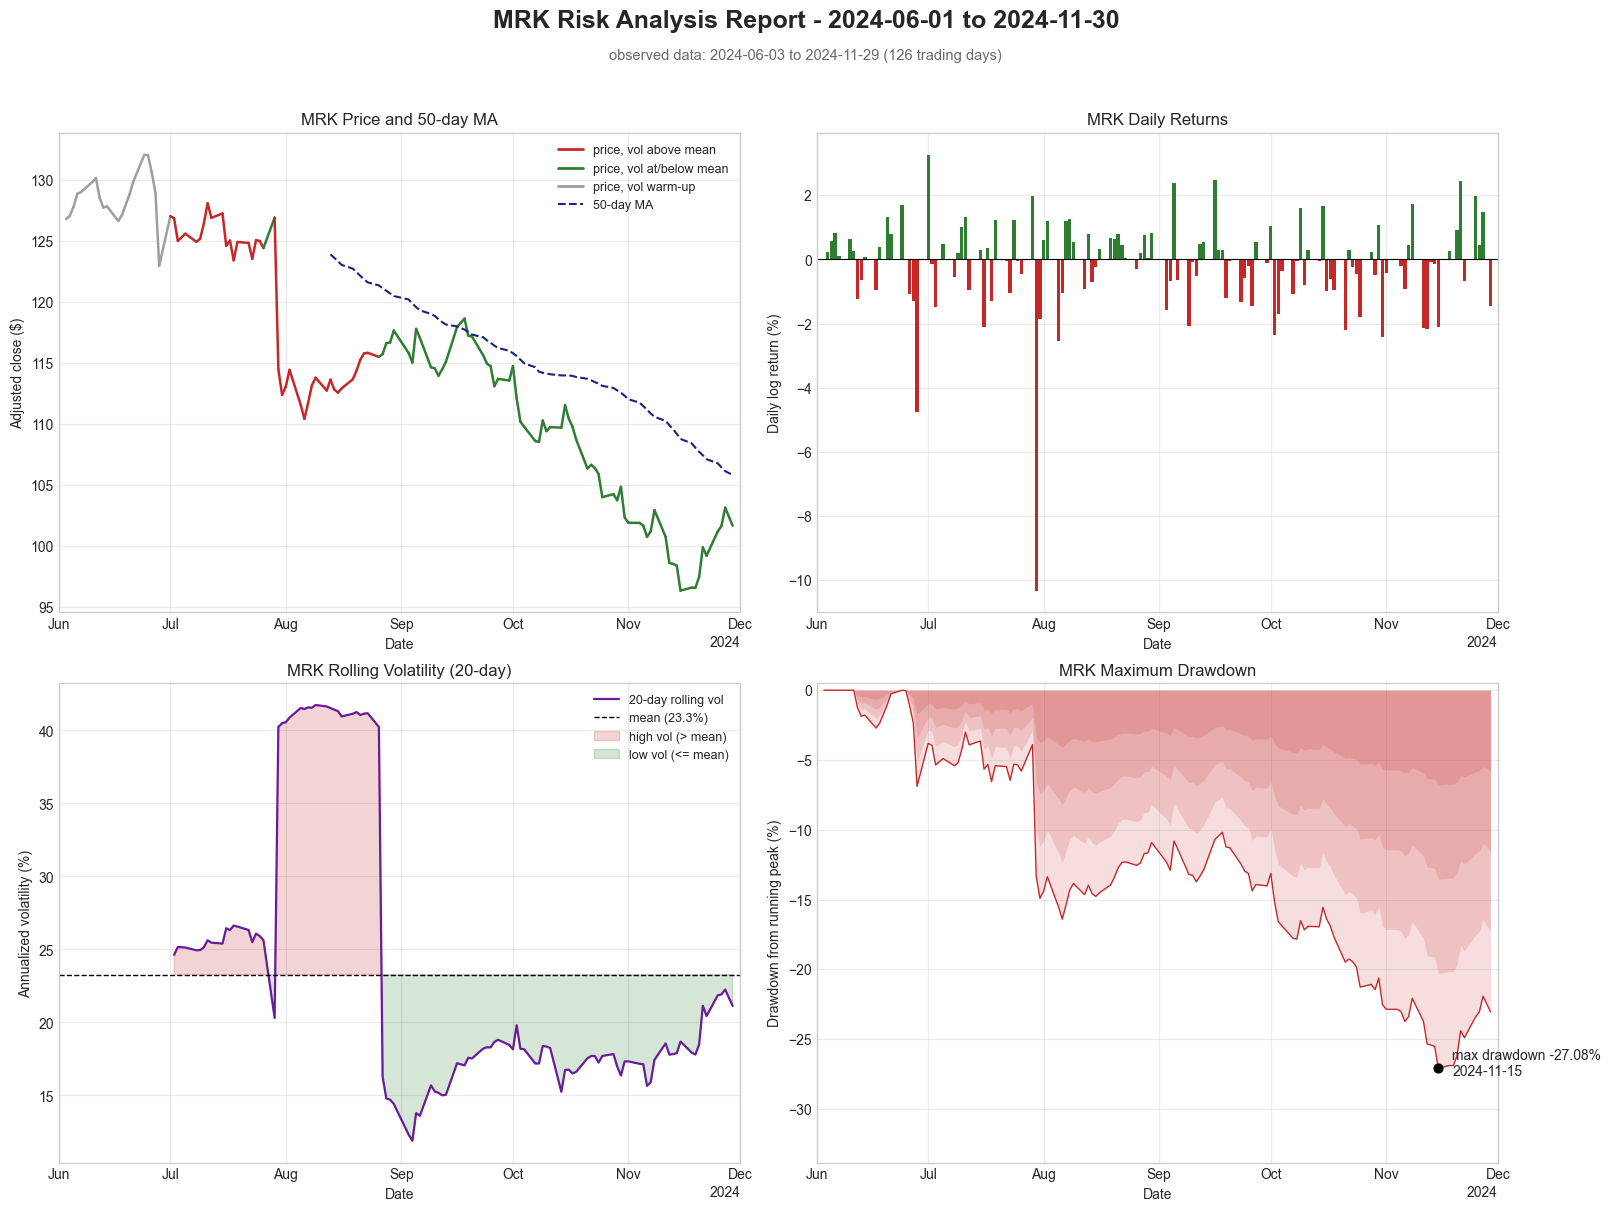

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')
fig.text(0.5, 0.955, f'observed data: {first_obs.date()} to {last_obs.date()} ({n_days} trading days)'
         + (f'  |  note: {coverage_note}' if short_coverage else ''),
         ha='center', fontsize=10.5, color=RED if short_coverage else 'dimgray')
fig.get_layout_engine().set(rect=(0, 0, 1, 0.94))

# top left: price coloured by volatility regime + 50 day MA
ax = axes[0, 0]
for i in range(1, n_days):
    vol = df['volatility'].iloc[i]
    color = GRAY if pd.isna(vol) else (RED if vol > mean_rolling_vol else GREEN)
    ax.plot(df.index[i - 1:i + 1], df['adj_close'].iloc[i - 1:i + 1], color=color, lw=1.8)
handles = [Line2D([], [], color=RED, lw=2, label='price, vol above mean'),
           Line2D([], [], color=GREEN, lw=2, label='price, vol at/below mean'),
           Line2D([], [], color=GRAY, lw=2, label='price, vol warm-up')]
if df['ma_50'].notna().any():
    ax.plot(df.index, df['ma_50'], color=NAVY, lw=1.5, ls='--')
    handles.append(Line2D([], [], color=NAVY, lw=1.5, ls='--', label=f'{MA_WINDOW}-day MA'))
else:
    ax.text(0.02, 0.04, f'{MA_WINDOW}-day MA not available: only {n_days} prices', transform=ax.transAxes, color=NAVY)
ax.legend(handles=handles, loc='best', fontsize=9)
ax.set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted close ($)')

# top right: daily returns
ax = axes[0, 1]
ax.bar(df.index, df['log_return'] * 100, width=0.9,
       color=np.where(df['log_return'] >= 0, GREEN, RED))
ax.axhline(0, color='black', lw=0.8)
ax.set(title=f'{ticker} Daily Returns', ylabel='Daily log return (%)')

# bottom left: rolling volatility
ax = axes[1, 0]
vol_pct, mean_pct = df['volatility'] * 100, mean_rolling_vol * 100
ax.plot(df.index, vol_pct, color=PURPLE, lw=1.6, label=f'{VOL_WINDOW}-day rolling vol')
ax.axhline(mean_pct, color='black', ls='--', lw=1, label=f'mean ({mean_pct:.1f}%)')
ax.fill_between(df.index, vol_pct, mean_pct, where=df['volatility'] > mean_rolling_vol,
                color=RED, alpha=0.2, interpolate=True, label='high vol (> mean)')
ax.fill_between(df.index, vol_pct, mean_pct, where=df['volatility'] <= mean_rolling_vol,
                color=GREEN, alpha=0.2, interpolate=True, label='low vol (<= mean)')
ax.legend(loc='best', fontsize=9)
ax.set(title=f'{ticker} Rolling Volatility (20-day)', ylabel='Annualized volatility (%)')

# bottom right: drawdown
ax = axes[1, 1]
dd_pct = df['drawdown'] * 100
for frac in [1.0, 0.75, 0.5, 0.25]:
    ax.fill_between(df.index, dd_pct * frac, 0, color=RED, alpha=0.15, lw=0)
ax.plot(df.index, dd_pct, color=RED, lw=1)
ax.scatter([max_dd_date], [max_dd * 100], color='black', zorder=3, s=40)
ax.annotate(f'max drawdown {max_dd:.2%}\n{max_dd_date.date()}', (max_dd_date, max_dd * 100),
            xytext=(10, -5), textcoords='offset points', fontsize=10)
ax.set_ylim(min(dd_pct.min() * 1.25, -1), 0.5)
ax.set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak (%)')

for ax in axes.flat:
    ax.grid(True, alpha=0.4)
    ax.set_xlabel('Date')
    ax.set_xlim(first_obs - pd.Timedelta(days=2), last_obs + pd.Timedelta(days=2))  # same dates on every panel
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
plt.show()

## summary table

- total return = last adj close / first adj close - 1
- annualized return = exp(sum(log returns) * 252 / n) - 1
- annualized volatility = whole-period std of log returns * sqrt(252) (not the same as the mean rolling vol)
- best/worst day and average up/down day use log returns
- positive days = positive returns / all non-missing returns (zero days count in the denominator)

In [12]:
def pct(value, signed=True, decimals=2):
    if pd.isna(value):
        return 'N/A'
    return f'{value:+.{decimals}%}' if signed else f'{value:.{decimals}%}'


metrics = {
    'Total Return': total_return,
    'Annualized Return': ann_return,
    'Annualized Volatility': ann_vol,
    'Sharpe Ratio': sharpe,
    'Maximum Drawdown': max_dd,
    'Best Day': returns.max() if n_returns else np.nan,
    'Worst Day': returns.min() if n_returns else np.nan,
    'Positive Days': (returns > 0).sum() / n_returns if n_returns else np.nan,
    'Average Up Day': up.mean() if len(up) else np.nan,
    'Average Down Day': down.mean() if len(down) else np.nan,
}
display_values = {
    'Total Return': pct(metrics['Total Return']),
    'Annualized Return': pct(metrics['Annualized Return']),
    'Annualized Volatility': pct(metrics['Annualized Volatility'], signed=False),
    'Sharpe Ratio': 'N/A' if pd.isna(sharpe) else f'{sharpe:.2f}',
    'Maximum Drawdown': pct(metrics['Maximum Drawdown']),
    'Best Day': pct(metrics['Best Day']),
    'Worst Day': pct(metrics['Worst Day']),
    'Positive Days': pct(metrics['Positive Days'], signed=False, decimals=1),
    'Average Up Day': pct(metrics['Average Up Day']),
    'Average Down Day': pct(metrics['Average Down Day']),
}
summary_table = pd.DataFrame({'Metric': list(display_values), 'Value': list(display_values.values())})

print(f'{ticker} | requested {start_date} to {end_date} | observed {first_obs.date()} to {last_obs.date()} ({n_days} days)')
print(f"{'Metric':<24}  {'Value':>8}")
print(f"{'-' * 24}  {'-' * 8}")
for name, value in display_values.items():
    print(f'{name:<24}  {value:>8}')
display(summary_table.set_index('Metric'))

MRK | requested 2024-06-01 to 2024-11-30 | observed 2024-06-03 to 2024-11-29 (126 days)
Metric                       Value
------------------------  --------
Total Return               -19.85%
Annualized Return          -35.98%
Annualized Volatility       24.09%
Sharpe Ratio                 -1.93
Maximum Drawdown           -27.08%
Best Day                    +3.26%
Worst Day                  -10.32%
Positive Days                47.2%
Average Up Day              +0.87%
Average Down Day            -1.11%


,Value
Metric,
Total Return,-19.85%
Annualized Return,-35.98%
Annualized Volatility,24.09%
Sharpe Ratio,-1.93
Maximum Drawdown,-27.08%
Best Day,+3.26%
Worst Day,-10.32%
Positive Days,47.2%
Average Up Day,+0.87%


## saving results for the batch run

Named values get glued with scrapbook so `03_run_all_stocks.py` can read them from each executed report without recalculating. Everything is stored as plain fractions. NaN becomes None, since JSON can't hold NaN. `report_complete` gets glued last, so a report that crashed halfway never has it.

In [13]:
def clean_number(value):
    value = float(value)
    return None if not np.isfinite(value) else value


sb.glue('ticker', ticker)
sb.glue('start_date', str(start_date))
sb.glue('end_date', str(end_date))
sb.glue('first_date', str(first_obs.date()))
sb.glue('last_date', str(last_obs.date()))
sb.glue('trading_days', int(n_days))
sb.glue('n_returns', int(n_returns))
sb.glue('coverage_note', coverage_note)
sb.glue('short_coverage', short_coverage)
sb.glue('data_quality_ok', data_quality_ok)
sb.glue('avg_daily_return', clean_number(returns.mean()))
sb.glue('avg_volatility', clean_number(mean_rolling_vol))
sb.glue('max_drawdown', clean_number(max_dd))
sb.glue('sharpe_ratio', clean_number(sharpe))
sb.glue('total_return', clean_number(total_return))
sb.glue('annualized_return', clean_number(ann_return))
sb.glue('annualized_volatility', clean_number(ann_vol))
sb.glue('report_complete', True)
print('glued results for', ticker)

glued results for MRK


## how to read this

- **total / annualized return**: what you'd have made holding over the observed dates. The annualized number blows up short windows (6 months x2 roughly), so don't read too much into it
- **annualized volatility**: typical size of daily moves, scaled to a year. The rolling chart shows whether risk was steady or came in bursts
- **Sharpe**: return over the 2% risk-free rate per unit of vol. Above ~1 is good for a single stock, negative means it didn't beat cash. On 6 months of data it's noisy
- **max drawdown**: the worst peak-to-trough drop in the window, i.e. the worst pain you'd have sat through
- **positive days / avg up vs down day**: tells you whether gains came from many small up days or a few big ones
- if the coverage line in red says the data ends early, the stock is being measured over a shorter period than the others